# Section 4. 가치평가 결과를 그래프로 표현하기

**목표:** 시간 경로 → payoff → 만기별 가격곡선 → 등고선 → 3차원 표면 → 파일 저장을 차례로 실습합니다.

이 노트북은 최신 강의록의 모든 코드 예제를 순서대로 담고 있습니다. 저장된 출력과 그림을 먼저 보고,
**커널 재시작 → 모두 실행**으로 직접 재현하세요. `data/` 폴더를 노트북과 같은 위치에 두어야 합니다.
다른 섹션의 실행 상태는 필요하지 않습니다. 설치 명령과 설명용 템플릿은 Markdown에 보관했습니다.

자료는 강의록에 포함된 **교육용 합성 자료**입니다. 단기금리와 변동성은 소수 단위이며,
그래프에서만 백분율로 표시합니다. 마지막에는 강의록 연습문제의 실행 가능한 참고 풀이가 있습니다.

In [1]:
%matplotlib inline
from IPython.display import display
print("Section 4: 그래프 실습을 시작합니다.")

Section 4: 그래프 실습을 시작합니다.


## 실습자료와 폴더 준비하기

**강의록의 폴더 배치 예시** — 배포본에서는 이 노트북과 `data/`가 같은 폴더에 있습니다.

```text
python_economics/
|-- 04_plotting_results.ipynb
|-- data/
|   |-- synthetic_market_time_series.csv
|   `-- european_option_market_data.csv
`-- output/
    `-- figures/
```

## Matplotlib 준비하기

### 코드 예제 2



<small>강의록: `section04_plotting.tex`, 161행 · 예제 2</small>

**필요할 때 한 번만 설치합니다.** 패키지가 준비되어 있다면 실행할 필요가 없습니다. 새 코드 셀에 복사하여 실행한 뒤 커널을 재시작하세요.

```python
%pip install matplotlib
```

### 이번 장에서 사용할 패키지 불러오기

Matplotlib은 그림을, NumPy는 수치배열을, pandas는 표 형태의 자료를 다룹니다.

<small>강의록: `section04_plotting.tex`, 168행 · 예제 3</small>

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

## 실습자료 읽기

### 두 실습자료 읽기

날짜를 날짜형으로 읽고 가격·금리·변동성에는 실수형을 지정합니다. 두 CSV는 함께 제공됩니다.

<small>강의록: `section04_plotting.tex`, 199행 · 예제 4</small>

In [3]:
data_dir = Path("data")
output_dir = Path("output")
figure_dir = output_dir / "figures"

market_path = data_dir / "synthetic_market_time_series.csv"
option_path = data_dir / "european_option_market_data.csv"

market_dtype = {
    "market_index": float,
    "stock_price": float,
    "market_return": float,
    "stock_return": float,
    "short_rate": float,
    "trading_volume": int,
    "data_source": "string",
}

market = pd.read_csv(
    market_path,
    encoding="utf-8-sig",
    dtype=market_dtype,
    parse_dates=["date"],
)

option_columns = [
    "option_type",
    "maturity_date",
    "time_to_maturity",
    "spot_price",
    "strike_price",
    "implied_volatility",
    "mid_price",
]

option_dtype = {
    "option_type": "string",
    "time_to_maturity": float,
    "spot_price": float,
    "strike_price": float,
    "implied_volatility": float,
    "mid_price": float,
}

options = pd.read_csv(
    option_path,
    encoding="utf-8-sig",
    usecols=option_columns,
    dtype=option_dtype,
    parse_dates=["maturity_date"],
)

### 그래프 작성 전 기본 확인

그리기 전에 자료의 행·열 수, 결측값, 변동성의 부호를 확인합니다.

<small>강의록: `section04_plotting.tex`, 254행 · 예제 5</small>

In [4]:
print("market shape:", market.shape)
print("options shape:", options.shape)

assert market["date"].notna().all()
assert market["stock_price"].notna().all()
assert options["mid_price"].notna().all()
assert options["implied_volatility"].notna().all()
assert (options["implied_volatility"] > 0.0).all()

market shape: (252, 8)
options shape: (42, 7)


**강의록에 제시된 예시 출력** — 위 실행 결과와 비교하세요.

```text
market shape: (252, 8)
options shape: (42, 7)
```

## Matplotlib의 기본 구조: Figure와 Axes

### 가장 기본적인 Matplotlib 구조

`fig`는 그림 전체, `ax`는 데이터를 그리는 좌표영역입니다. 제목·축·격자를 붙여 보세요.

<small>강의록: `section04_plotting.tex`, 281행 · 예제 7</small>

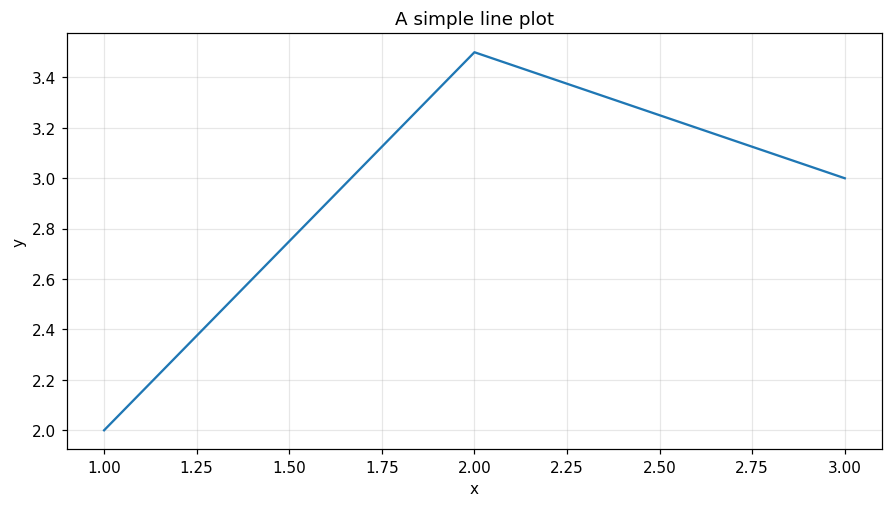

In [5]:
fig, ax = plt.subplots(figsize=(8.0, 4.5), layout="constrained")

ax.plot([1.0, 2.0, 3.0], [2.0, 3.5, 3.0])

ax.set_title("A simple line plot")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True, alpha=0.3)

plt.show()

## 선 그래프: 가격의 시간 경로

### 날짜별 합성 주가의 선 그래프

날짜순으로 정렬한 뒤 주가 경로를 연결합니다. 정렬되지 않은 자료를 연결하면 선이 뒤섞일 수 있습니다.

<small>강의록: `section04_plotting.tex`, 330행 · 예제 8</small>

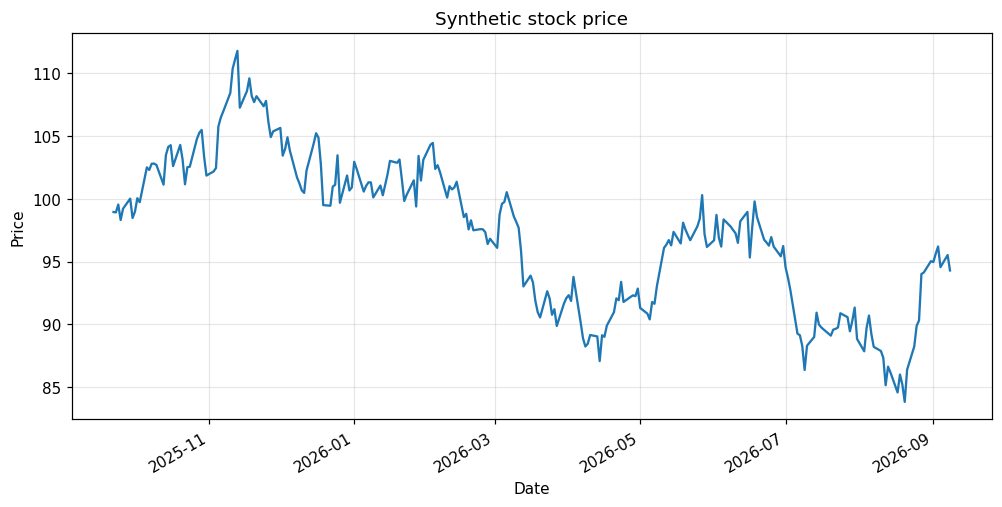

In [6]:
market = market.sort_values("date").copy()

fig, ax = plt.subplots(figsize=(9.0, 4.5), layout="constrained")
ax.plot(market["date"], market["stock_price"], linewidth=1.5)

ax.set_title("Synthetic stock price")
ax.set_xlabel("Date")
ax.set_ylabel("Price")
ax.grid(True, alpha=0.3)

fig.autofmt_xdate()
plt.show()

## Payoff diagram: 옵션계약의 형태 나타내기

### 유럽형 옵션의 만기 payoff

만기 payoff는 콜의 경우 $(S_T-K)^+$, 풋의 경우 $(K-S_T)^+$입니다. 매수 시 지급한 premium은 포함하지 않습니다.

<small>강의록: `section04_plotting.tex`, 377행 · 예제 9</small>

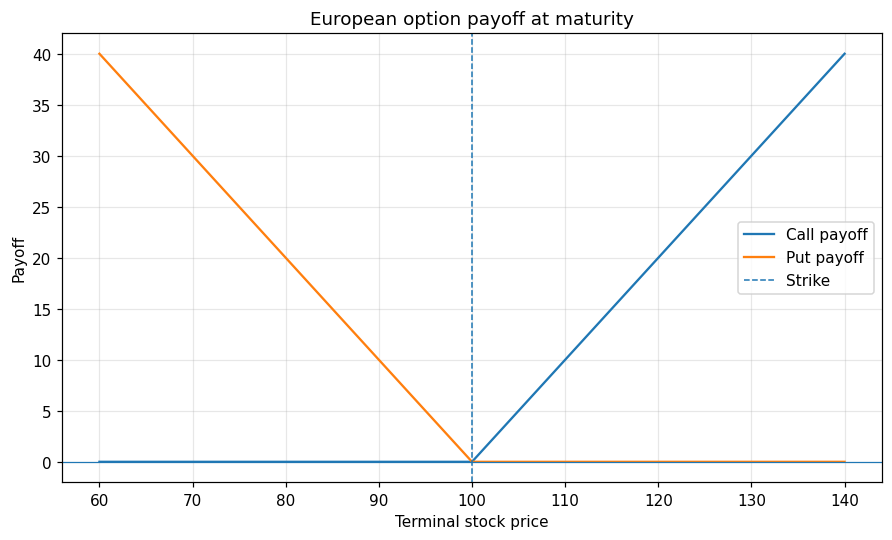

In [7]:
terminal_prices = np.linspace(60.0, 140.0, num=401)
strike = 100.0

call_payoff = np.maximum(terminal_prices - strike, 0.0)
put_payoff = np.maximum(strike - terminal_prices, 0.0)

fig, ax = plt.subplots(figsize=(8.0, 4.8), layout="constrained")
ax.plot(terminal_prices, call_payoff, label="Call payoff")
ax.plot(terminal_prices, put_payoff, label="Put payoff")
ax.axvline(
    strike,
    linestyle="--",
    linewidth=1.0,
    label="Strike",
)
ax.axhline(0.0, linewidth=0.8)

ax.set_title("European option payoff at maturity")
ax.set_xlabel("Terminal stock price")
ax.set_ylabel("Payoff")
ax.grid(True, alpha=0.3)
ax.legend()

plt.show()

### 코드 예제 10

단순 만기 profit은 payoff에서 premium을 뺀 값입니다. 여기서는 premium의 시간가치를 생략합니다.

<small>강의록: `section04_plotting.tex`, 418행 · 예제 10</small>

In [8]:
premium = 8.0
call_profit = call_payoff - premium
print("Payoff/profit at terminal price 100:", call_payoff[200], call_profit[200])

Payoff/profit at terminal price 100: 0.0 -8.0


## 여러 개의 선: 만기별 옵션 가격곡선

### 행사가격에 따른 콜옵션 mid price

만기별로 그룹을 나누고 각 그룹의 행사가격을 정렬합니다. 콜 가격은 행사가격이 커질수록 감소하는지 확인하세요.

<small>강의록: `section04_plotting.tex`, 434행 · 예제 11</small>

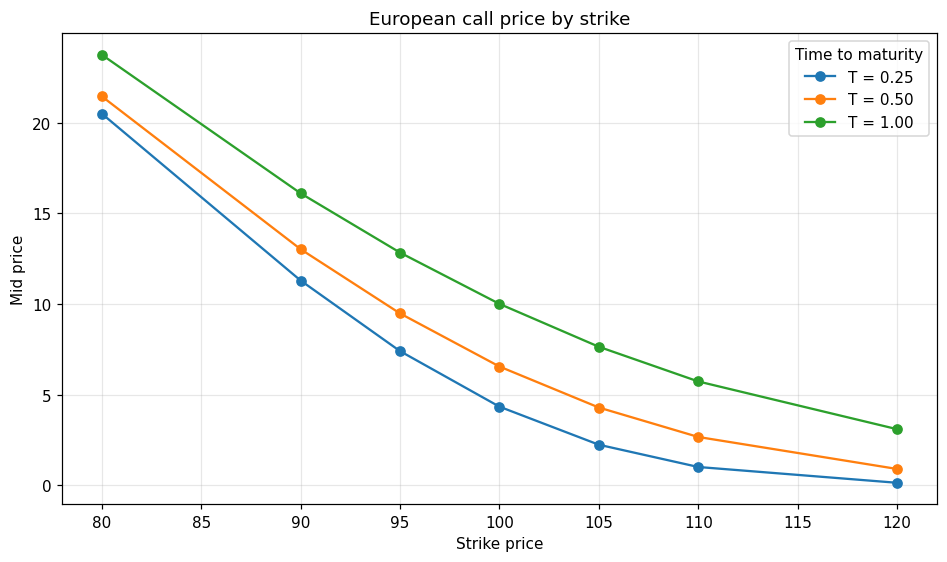

In [9]:
call_options = options.loc[options["option_type"] == "call"].copy()

fig, ax = plt.subplots(figsize=(8.5, 5.0), layout="constrained")
grouped_options = call_options.groupby("time_to_maturity")

for time_to_maturity, group in grouped_options:
    group = group.sort_values("strike_price")
    ax.plot(
        group["strike_price"],
        group["mid_price"],
        marker="o",
        label=f"T = {time_to_maturity:.2f}",
    )

ax.set_title("European call price by strike")
ax.set_xlabel("Strike price")
ax.set_ylabel("Mid price")
ax.grid(True, alpha=0.3)
ax.legend(title="Time to maturity")

plt.show()
option_price_figure = fig  # 나중에 이 가격곡선을 PDF로 저장합니다.

## 내재변동성 곡선에서 volatility surface로

### moneyness에 따른 내재변동성 곡선

`moneyness = K/S0`를 가로축으로 사용합니다. 소수 0.20을 20%로 표시하려면 `PercentFormatter(xmax=1.0)`를 사용합니다.

<small>강의록: `section04_plotting.tex`, 502행 · 예제 12</small>

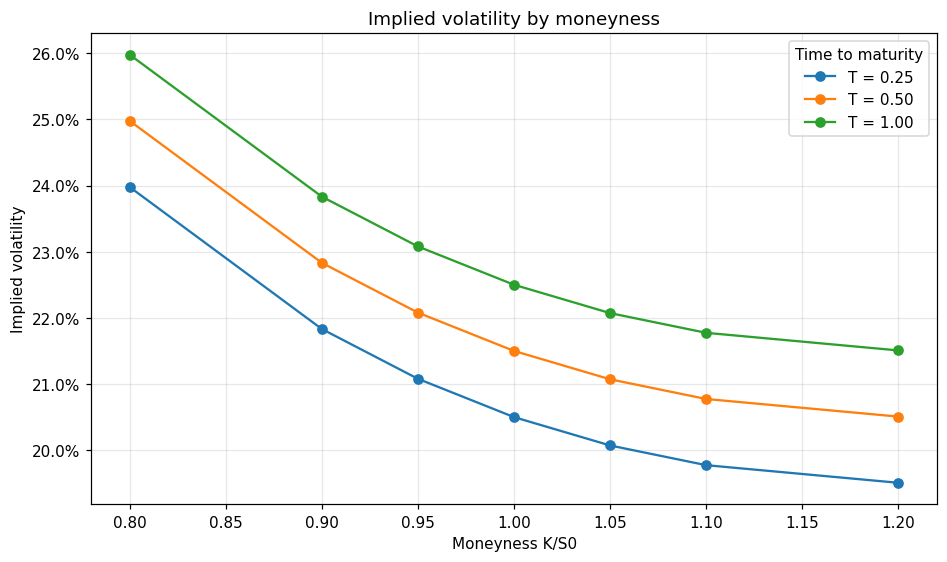

In [10]:
call_options["moneyness"] = (
    call_options["strike_price"] / call_options["spot_price"]
)

fig, ax = plt.subplots(figsize=(8.5, 5.0), layout="constrained")
grouped_options = call_options.groupby("time_to_maturity")

for time_to_maturity, group in grouped_options:
    group = group.sort_values("moneyness")
    ax.plot(
        group["moneyness"],
        group["implied_volatility"],
        marker="o",
        label=f"T = {time_to_maturity:.2f}",
    )

ax.set_title("Implied volatility by moneyness")
ax.set_xlabel("Moneyness K/S0")
ax.set_ylabel("Implied volatility")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0))
ax.grid(True, alpha=0.3)
ax.legend(title="Time to maturity")

plt.show()

## 두 변수의 결과를 위한 격자 만들기

### long format을 표면용 격자로 변환하기

행은 만기, 열은 moneyness입니다. 빠진 조합이 없는지 확인한 뒤 `meshgrid()`로 동일한 모양의 좌표배열을 만듭니다.

<small>강의록: `section04_plotting.tex`, 558행 · 예제 13</small>

In [11]:
volatility_table = (
    call_options.pivot(
        index="time_to_maturity",
        columns="moneyness",
        values="implied_volatility",
    )
    .sort_index()
    .sort_index(axis=1)
)

if volatility_table.isna().any().any():
    raise ValueError("The strike-maturity grid is incomplete.")

moneyness_grid, maturity_grid = np.meshgrid(volatility_table.columns.to_numpy(), volatility_table.index.to_numpy())
volatility_grid = volatility_table.to_numpy()

print(volatility_table.shape)
print(moneyness_grid.shape)
print(maturity_grid.shape)
print(volatility_grid.shape)

(3, 7)
(3, 7)
(3, 7)
(3, 7)


**강의록에 제시된 예시 출력** — 위 실행 결과와 비교하세요.

```text
(3, 7)
(3, 7)
(3, 7)
(3, 7)
```

## 등고선 그림: 두 변수의 결과를 평면에서 보기

### volatility surface의 2차원 등고선 그림

색을 통해 내재변동성의 크기를 비교합니다. 등고선은 두 입력에 따른 값의 차이를 평면에서 읽기 좋습니다.

<small>강의록: `section04_plotting.tex`, 618행 · 예제 15</small>

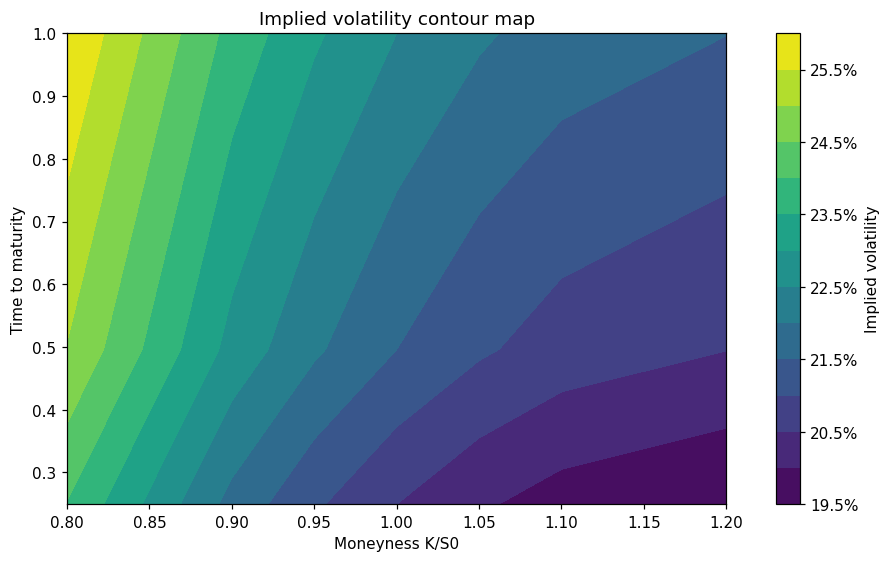

In [12]:
fig, ax = plt.subplots(figsize=(8.0, 5.0), layout="constrained")

contour = ax.contourf(
    moneyness_grid,
    maturity_grid,
    volatility_grid,
    levels=12,
    cmap="viridis",
)

ax.set_title("Implied volatility contour map")
ax.set_xlabel("Moneyness K/S0")
ax.set_ylabel("Time to maturity")

colorbar = fig.colorbar(contour, ax=ax)
colorbar.set_label("Implied volatility")
colorbar.ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0))

plt.show()

## 3차원 그래프: volatility surface

### 3차원 implied volatility surface

동일한 격자를 3차원 표면으로 표현합니다. 점은 원래 격자점이고 면은 그 점들을 연결한 표현입니다.

<small>강의록: `section04_plotting.tex`, 661행 · 예제 16</small>

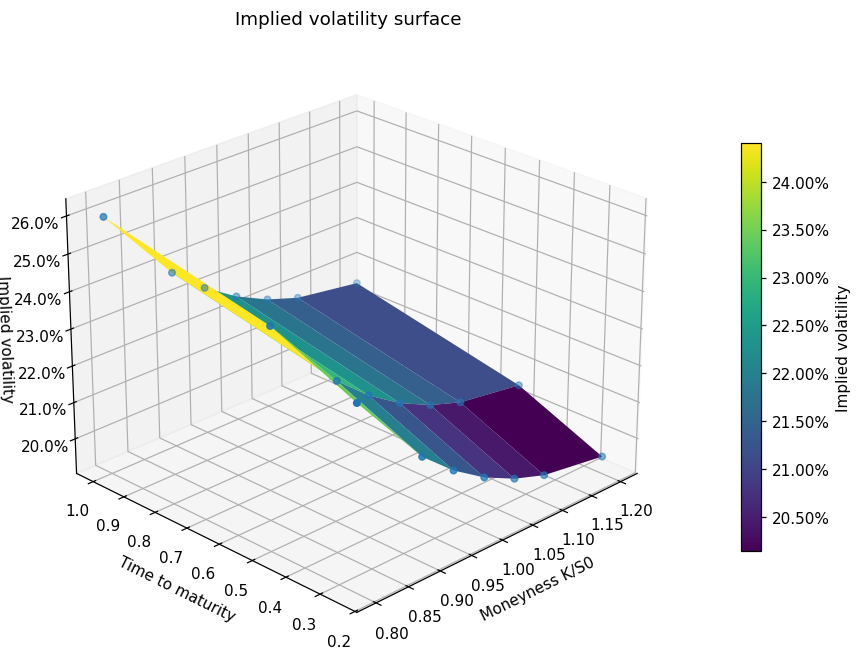

In [13]:
fig = plt.figure(figsize=(9.0, 6.0), layout="constrained")
ax = fig.add_subplot(111, projection="3d")

surface = ax.plot_surface(
    moneyness_grid,
    maturity_grid,
    volatility_grid,
    cmap="viridis",
    linewidth=0.4,
    antialiased=True,
)

ax.scatter(
    moneyness_grid,
    maturity_grid,
    volatility_grid,
    s=18,
)

ax.set_title("Implied volatility surface")
ax.set_xlabel("Moneyness K/S0")
ax.set_ylabel("Time to maturity")
ax.set_zlabel("Implied volatility")
ax.zaxis.set_major_formatter(PercentFormatter(xmax=1.0))
ax.view_init(elev=25.0, azim=-135.0)

colorbar = fig.colorbar(
    surface,
    ax=ax,
    shrink=0.65,
    pad=0.10,
)
colorbar.set_label("Implied volatility")
colorbar.ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0))

plt.show()

### 코드 예제 17

같은 그림의 시점만 변경합니다. 노트북에서 변경 결과가 보이도록 `display(fig)`를 덧붙였습니다.

<small>강의록: `section04_plotting.tex`, 724행 · 예제 17</small>

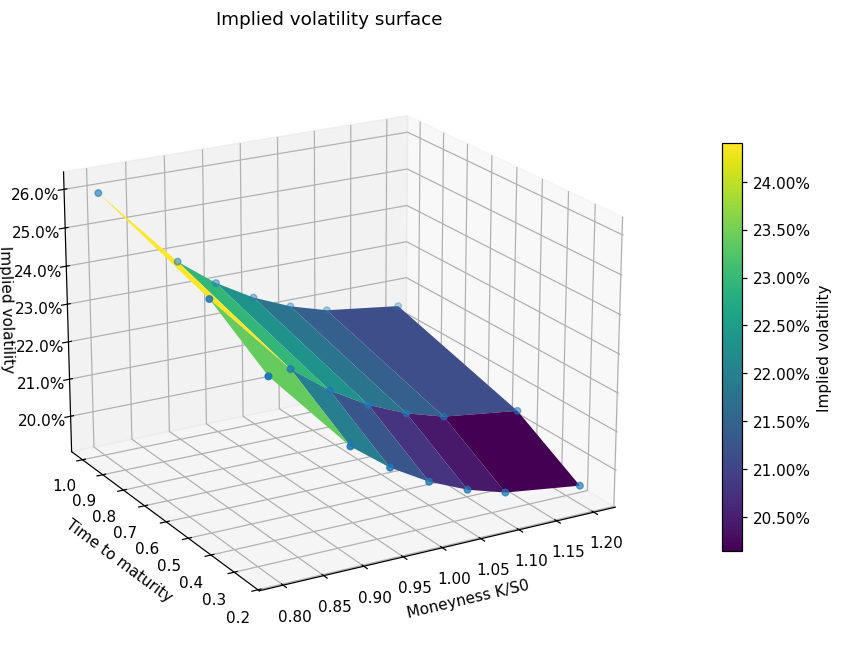

In [14]:
ax.view_init(elev=20.0, azim=-120.0)
display(fig)

## 다른 두 변수 함수에도 같은 구조 사용하기

### 두 변수 함수의 그래프를 만드는 기본 구조

아래는 변수 이름과 함수를 채워 넣기 위한 일반 템플릿입니다.

<small>강의록: `section04_plotting.tex`, 754행 · 예제 18</small>

**설명용 템플릿:** `x_min`, `value_function` 등은 아직 정해지지 않았으므로 그대로 실행하지 않습니다. 아래 보충 예제는 값을 채워 실제로 실행합니다.

```python
x_values = np.linspace(x_min, x_max, num=number_of_x_points)
y_values = np.linspace(y_min, y_max, num=number_of_y_points)

x_grid, y_grid = np.meshgrid(x_values, y_values)
z_grid = value_function(x_grid, y_grid)
```

**보충 예제:** $z=(x-y)^+$를 계산하여 격자의 모양을 확인합니다.

In [15]:
x_min, x_max = 80.0, 120.0
y_min, y_max = 90.0, 110.0
number_of_x_points, number_of_y_points = 5, 3
value_function = lambda x, y: np.maximum(x - y, 0.0)
x_values = np.linspace(x_min, x_max, num=number_of_x_points)
y_values = np.linspace(y_min, y_max, num=number_of_y_points)

x_grid, y_grid = np.meshgrid(x_values, y_values)
z_grid = value_function(x_grid, y_grid)
print("x/y/z shapes:", x_grid.shape, y_grid.shape, z_grid.shape)
print(z_grid)

x/y/z shapes: (3, 5) (3, 5) (3, 5)
[[ 0.  0. 10. 20. 30.]
 [ 0.  0.  0. 10. 20.]
 [ 0.  0.  0.  0. 10.]]


## 그래프를 파일로 저장하기

### 코드 예제 19

존재하지 않는 출력 폴더는 만들어 줍니다. 이미 존재해도 오류가 나지 않습니다.

<small>강의록: `section04_plotting.tex`, 779행 · 예제 19</small>

In [16]:
figure_dir.mkdir(parents=True, exist_ok=True)

### volatility surface를 PNG로 저장하기

보관한 Figure 객체를 PNG로 저장합니다. `True`는 지정한 위치에 파일이 만들어졌다는 뜻입니다.

<small>강의록: `section04_plotting.tex`, 788행 · 예제 20</small>

In [17]:
surface_path = figure_dir / "implied_volatility_surface.png"
fig.savefig(surface_path, dpi=300, bbox_inches="tight")

plt.show()
print(surface_path.exists())

True


**강의록에 제시된 예시 출력** — 위 실행 결과와 비교하세요.

```text
True
```

### 코드 예제 22

파일명과 내용이 일치하도록 앞서 보관한 콜옵션 가격곡선 Figure를 PDF로 저장합니다. 원고의 `fig` 대신 `option_price_figure`를 사용합니다.

<small>강의록: `section04_plotting.tex`, 809행 · 예제 22</small>

In [18]:
pdf_path = figure_dir / "option_price_curves.pdf"

option_price_figure.savefig(pdf_path, bbox_inches="tight")
print("Saved:", pdf_path.as_posix(), pdf_path.exists())

Saved: output/figures/option_price_curves.pdf True


## 직접 해보기

### 코드 예제 23

선택 연습의 입력입니다. 두 변수에 대한 payoff 표면은 뒤의 참고 풀이에서 완성합니다.

<small>강의록: `section04_plotting.tex`, 959행 · 예제 23</small>

In [19]:
terminal_price_values = np.linspace(70.0, 130.0, num=61)
strike_values = np.linspace(80.0, 120.0, num=41)

## 연습문제 참고 풀이

먼저 직접 작성한 뒤 비교하세요. 아래 셀은 강의록에 완성 코드가 없는 연습문제를 위한 **추가 코드**입니다.

### 연습 1. 단기금리 경로

금리를 백분율로 표시하고 PNG 파일로 저장합니다.

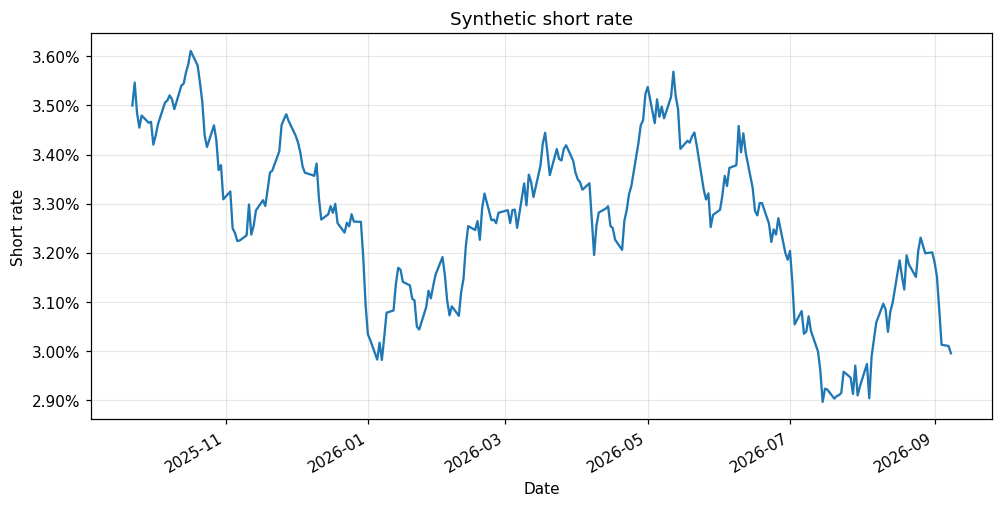

In [20]:
fig_rate, ax_rate = plt.subplots(figsize=(9.0, 4.5), layout="constrained")
ax_rate.plot(market["date"], market["short_rate"])
ax_rate.set(title="Synthetic short rate", xlabel="Date", ylabel="Short rate")
ax_rate.yaxis.set_major_formatter(PercentFormatter(xmax=1.0))
ax_rate.grid(True, alpha=0.3)
fig_rate.autofmt_xdate()
fig_rate.savefig(figure_dir / "short_rate_path.png", dpi=300, bbox_inches="tight")
plt.show()

### 연습 2. 콜옵션 payoff와 profit

단순 손익분기점은 $K+\mathrm{premium}=108$입니다.

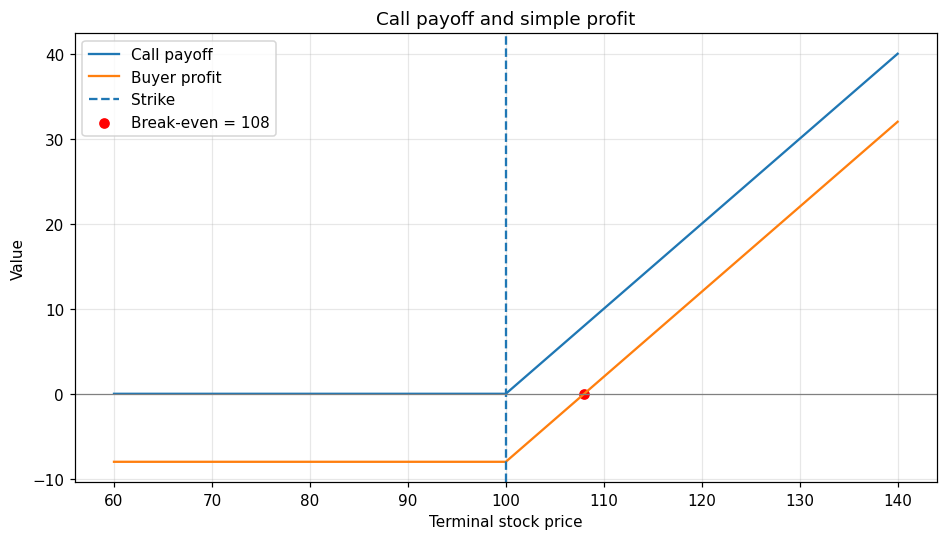

In [21]:
terminal_prices = np.linspace(60.0, 140.0, num=401)
strike, premium = 100.0, 8.0
call_payoff = np.maximum(terminal_prices - strike, 0.0)
fig_profit, ax_profit = plt.subplots(figsize=(8.5, 4.8), layout="constrained")
ax_profit.plot(terminal_prices, call_payoff, label="Call payoff")
ax_profit.plot(terminal_prices, call_payoff - premium, label="Buyer profit")
ax_profit.axvline(strike, linestyle="--", label="Strike")
ax_profit.axhline(0.0, color="gray", linewidth=0.8)
ax_profit.scatter([strike + premium], [0.0], color="red", label="Break-even = 108")
ax_profit.set(title="Call payoff and simple profit", xlabel="Terminal stock price", ylabel="Value")
ax_profit.legend()
ax_profit.grid(True, alpha=0.3)
plt.show()

### 연습 3. 풋옵션 가격곡선

각 만기에서 행사가격이 커지면 풋 가격도 증가하는지 확인합니다.

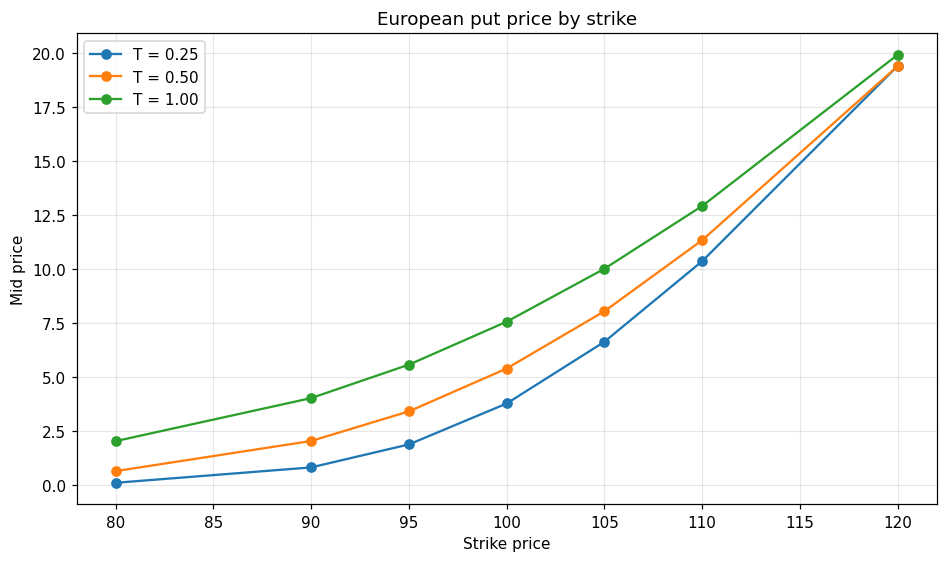

In [22]:
put_options = options.loc[options["option_type"] == "put"].copy()
fig_put, ax_put = plt.subplots(figsize=(8.5, 5.0), layout="constrained")
for time_to_maturity, group in put_options.groupby("time_to_maturity"):
    group = group.sort_values("strike_price")
    ax_put.plot(group["strike_price"], group["mid_price"], marker="o", label=f"T = {time_to_maturity:.2f}")
ax_put.set(title="European put price by strike", xlabel="Strike price", ylabel="Mid price")
ax_put.legend()
ax_put.grid(True, alpha=0.3)
plt.show()

### 연습 4–5. 옵션 가격의 등고선과 표면

같은 가격격자를 두 가지 방식으로 표시합니다.

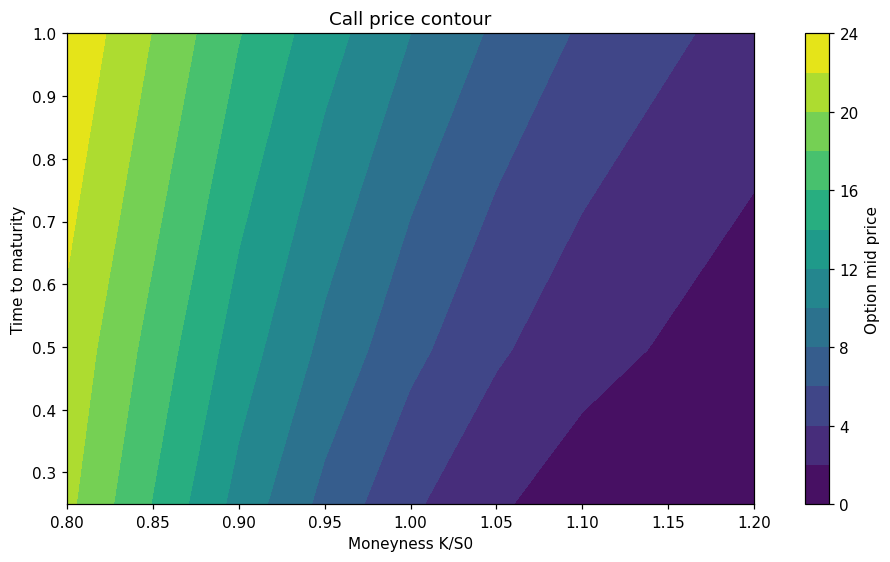

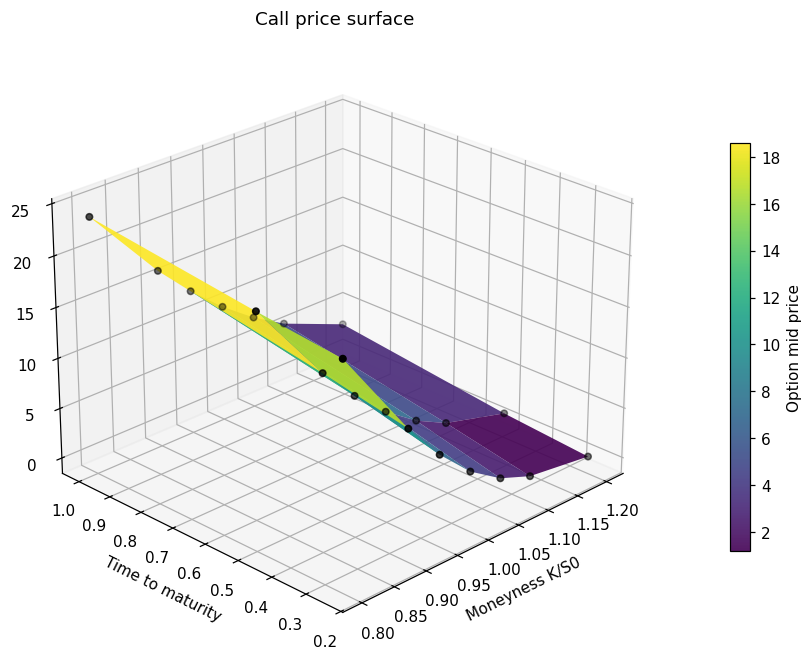

In [23]:
price_table = call_options.pivot(index="time_to_maturity", columns="moneyness", values="mid_price")
price_table = price_table.sort_index().sort_index(axis=1)
assert not price_table.isna().any().any()
money_grid, time_grid = np.meshgrid(price_table.columns.to_numpy(), price_table.index.to_numpy())
mid_grid = price_table.to_numpy()

fig_contour, ax_contour = plt.subplots(figsize=(8.0, 5.0), layout="constrained")
contour = ax_contour.contourf(money_grid, time_grid, mid_grid, levels=12, cmap="viridis")
ax_contour.set(title="Call price contour", xlabel="Moneyness K/S0", ylabel="Time to maturity")
fig_contour.colorbar(contour, ax=ax_contour, label="Option mid price")
plt.show()

fig_surface = plt.figure(figsize=(9.0, 6.0), layout="constrained")
ax_surface = fig_surface.add_subplot(111, projection="3d")
surface = ax_surface.plot_surface(money_grid, time_grid, mid_grid, cmap="viridis", alpha=0.9)
ax_surface.scatter(money_grid, time_grid, mid_grid, s=18, color="black")
ax_surface.set(title="Call price surface", xlabel="Moneyness K/S0", ylabel="Time to maturity", zlabel="Mid price")
ax_surface.view_init(elev=25.0, azim=-135.0)
fig_surface.colorbar(surface, ax=ax_surface, shrink=0.65, pad=0.10, label="Option mid price")
plt.show()

### 선택 연습. 두 변수 call payoff surface

꺾이는 경계는 $S_T=K$입니다.

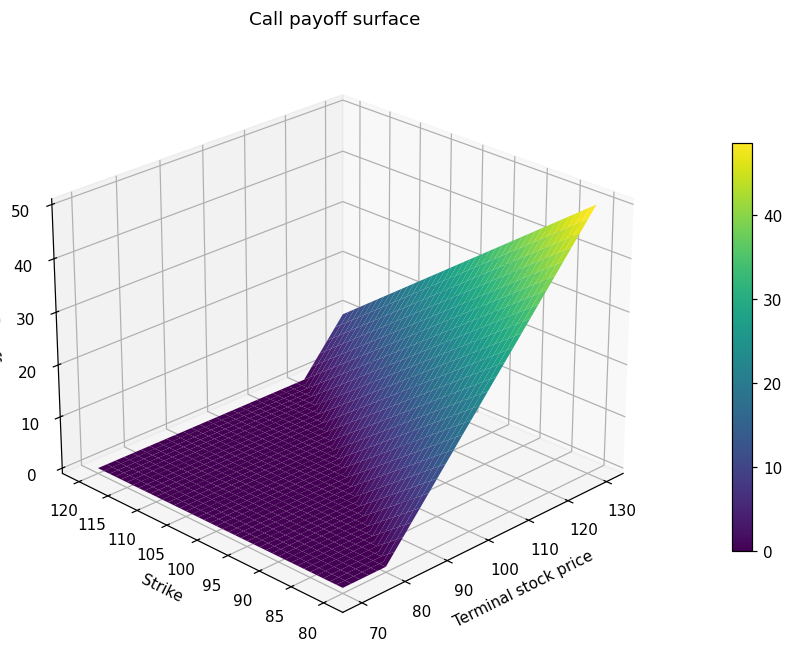

In [24]:
terminal_price_values = np.linspace(70.0, 130.0, num=61)
strike_values = np.linspace(80.0, 120.0, num=41)
terminal_grid, payoff_strike_grid = np.meshgrid(terminal_price_values, strike_values)
payoff_surface = np.maximum(terminal_grid - payoff_strike_grid, 0.0)
fig_payoff = plt.figure(figsize=(9.0, 6.0), layout="constrained")
ax_payoff = fig_payoff.add_subplot(111, projection="3d")
surface = ax_payoff.plot_surface(terminal_grid, payoff_strike_grid, payoff_surface, cmap="viridis")
ax_payoff.set(title="Call payoff surface", xlabel="Terminal stock price", ylabel="Strike", zlabel="Payoff")
ax_payoff.view_init(elev=25.0, azim=-135.0)
fig_payoff.colorbar(surface, ax=ax_payoff, shrink=0.65, pad=0.10)
plt.show()

## 마무리 확인

- 선을 연결하기 전에 가로축을 정렬했나요?
- payoff와 profit을 구분할 수 있나요?
- 원래 격자점과 이를 연결한 표면을 구분할 수 있나요?
- `output/figures/`에 PNG와 PDF가 저장되었나요?

**원고와의 실행상 차이:** 설치 셀과 일반 템플릿은 Markdown으로 보관하고, 템플릿에는 실행 예제를 추가했습니다.
그림 시점 변경 결과를 다시 표시하고, PDF 저장에는 해당 가격곡선을 보관한 Figure를 사용했습니다.